In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

In [14]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing/espectros_correction_msc.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/pre_processing"
output_path = os.path.join(output_dir, 'espectros_transformada_log.csv')

In [15]:
df = pd.read_csv(input_path)
data = df.values

In [16]:
# Evita log de zero ou valores negativos
data[data <= 0] = 1e-6
data_log = -np.log(data)

In [17]:
df_espectros = pd.DataFrame(data_log, columns=df.columns)
df_espectros.head()

,Banda_0,Banda_1,Banda_2,Banda_3,Banda_4,Banda_5,Banda_6,Banda_7,Banda_8,Banda_9,...,Banda_246,Banda_247,Banda_248,Banda_249,Banda_250,Banda_251,Banda_252,Banda_253,Banda_254,Banda_255
0,13.815511,-8.182853,-8.123572,-8.169868,-8.171877,-8.104436,-8.126726,-8.134047,-8.025169,-8.210261,...,-7.981229,-7.951658,-7.909516,-7.977580,-8.005220,-7.959133,-8.053803,-8.035572,-8.093645,-8.214116
1,13.815511,-8.135588,-8.179446,-8.180378,-8.139479,-8.212476,-8.097849,-8.142388,-8.091757,-8.173833,...,-7.888032,-7.961424,-7.864026,-7.906585,-8.046983,-7.955607,-7.865304,-8.045917,-8.087676,-8.068058
2,-8.140350,-8.190071,-8.144773,-8.143669,-8.072728,-8.084516,-8.067974,-8.010349,-8.009086,-7.991236,...,-7.640427,-7.530456,-7.859419,-7.909513,-7.755906,-7.941116,-7.902508,-8.239447,-8.000201,-8.134793
3,-8.256433,-8.181329,-7.954173,-7.951594,-7.989602,-8.513571,-8.079883,-8.202651,-8.162683,-7.999499,...,-7.798389,-7.832421,-7.793863,-7.920112,-7.866740,-7.720150,-7.775553,-8.011733,-7.872347,-8.127569
4,-8.144799,-8.192364,-8.108923,-8.135427,-8.134380,-8.092677,-8.054844,-8.082801,-8.145835,-8.111069,...,-7.754153,-7.833629,-7.705501,-7.699048,-7.779861,-7.787298,-7.817944,-7.892687,-8.039992,-8.134380


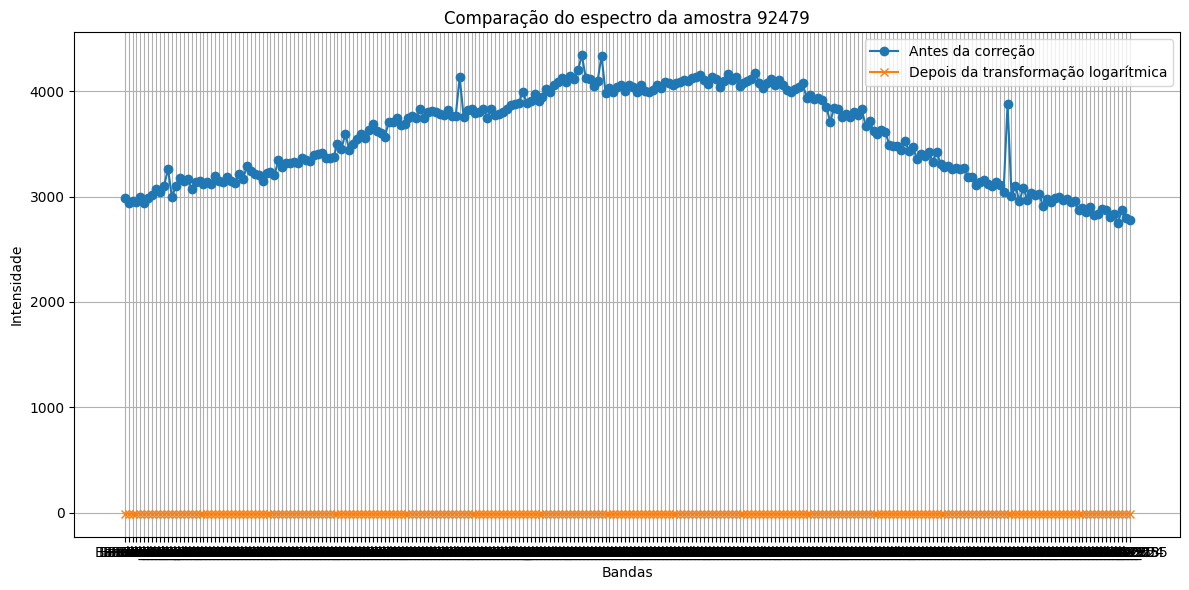

In [ ]:
# Escolhe a última amostra
indice_amostra = df.shape[0] - 1

# Converte colunas para float se forem numéricas
try:
    bandas = df.columns.astype(float)
except:
    bandas = df.columns

plt.figure(figsize=(12, 6))
plt.plot(bandas, df.iloc[indice_amostra, :], label='Antes da correção', marker='o')
plt.plot(bandas, df_espectros.iloc[indice_amostra, :], label='Depois da transformação logarítmica', marker='x')
plt.xlabel('Bandas')
plt.ylabel('Intensidade')
plt.title(f'Comparação do espectro da amostra {indice_amostra}')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
df_espectros.to_csv(output_path, index=False)
print("Arquivo corrigido salvo com sucesso em:\n", output_path)